In [1]:
import pandas as pd

BASE = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data"
train = pd.read_csv(f"{BASE}/train.csv")
test = pd.read_csv(f"{BASE}/test.csv")

print(train.shape, test.shape)
train.head(10)



(10003, 2) (3080, 2)


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival
5,When did you send me my new card?,card_arrival
6,Do you have info about the card on delivery?,card_arrival
7,What do I do if I still have not received my n...,card_arrival
8,Does the package with my card have tracking?,card_arrival
9,I ordered my card but it still isn't here,card_arrival


In [2]:
counts = train["category"].value_counts()
counts

category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
                                                   ... 
lost_or_stolen_card                                  82
card_swallowed                                       61
card_acceptance                                      59
virtual_card_not_working                             41
contactless_not_working                              35
Name: count, Length: 77, dtype: int64

In [3]:
print("Most common:")
print(counts.head(3))
print()
print("Least common:")
print(counts.tail(3))

Most common:
category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
Name: count, dtype: int64

Least common:
category
card_acceptance             59
virtual_card_not_working    41
contactless_not_working     35
Name: count, dtype: int64


In [4]:
print("Number of categories:", counts.size)
print("Biggest:", counts.max())
print("Smallest:", counts.min())
print("Ratio biggest/smallest:", round(counts.max() / counts.min(), 1))

Number of categories: 77
Biggest: 187
Smallest: 35
Ratio biggest/smallest: 5.3


<Axes: title={'center': 'Messages per category'}, xlabel='category'>

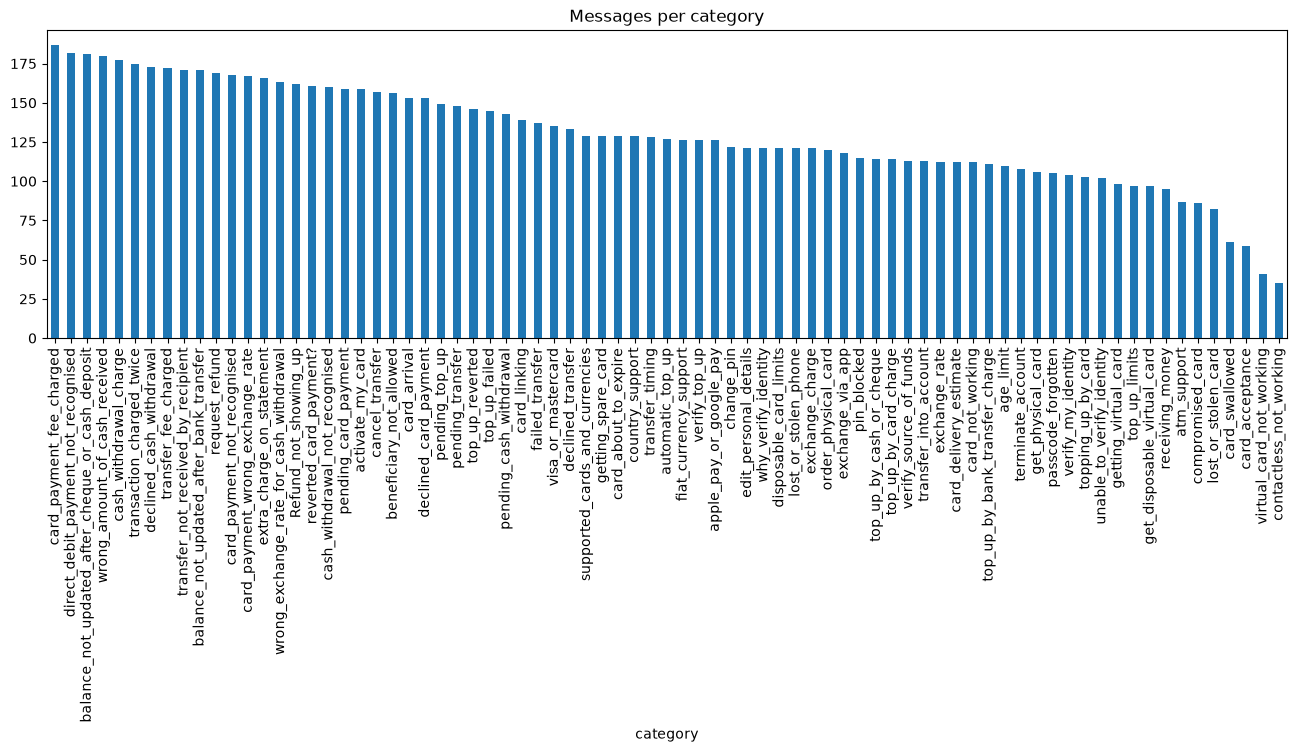

In [5]:
counts.plot(kind="bar", figsize=(16, 4), title="Messages per category")

In [6]:
pd.set_option("display.max_colwidth", None)

In [7]:
train.sample(15, random_state=1)

,text,category
7872,I need more physical cards.,getting_spare_card
1520,Someone stole my wallet with my card in it while vacationing in Spain. I really need my card blocked and a new one ordered.,lost_or_stolen_card
6319,I was charged for the same thing twice,transaction_charged_twice
5197,I made a purchase earlier today but it is still listed as pending- when will it go through?,pending_card_payment
9019,Will there be a cost if I exchange currency?,exchange_charge
4397,Are there any restrictions for the disposable cards that I need to be aware of?,disposable_card_limits
5183,My card payment has been on pending forever. What is the problem? It should have gone through at some time by now.,pending_card_payment
659,Why did you guys charge me an extra €1?,extra_charge_on_statement
5819,My refund is not here yet,Refund_not_showing_up
5519,"I did not receive my purchase, how do I cancel it?",request_refund


In [8]:
print("Smallest:", counts.min())

Smallest: 35


In [9]:
print("Least common:")
print(counts.tail(10))

Least common:
category
top_up_limits                  97
get_disposable_virtual_card    97
receiving_money                95
atm_support                    87
compromised_card               86
lost_or_stolen_card            82
card_swallowed                 61
card_acceptance                59
virtual_card_not_working       41
contactless_not_working        35
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    train,
    test_size=0.15,              # 15% goes to validation
    random_state=42,             # same split every run (reproducible)
    stratify=train["category"],  # keep category proportions equal
)

print("train:", train_df.shape)
print("val:  ", val_df.shape)

train: (8502, 2)
val:   (1501, 2)


In [11]:
cat = "contactless_not_working"
print("in train_df:", (train_df["category"] == cat).sum())
print("in val_df:  ", (val_df["category"] == cat).sum())

in train_df: 30
in val_df:   5


In [12]:
def norm(texts):
    return texts.str.lower().str.strip()

In [13]:
train_texts = set(norm(train_df["text"]))
test_texts = set(norm(test["text"]))

overlap = train_texts & test_texts
print("Messages in both train and test:", len(overlap))
list(overlap)[:10]

Messages in both train and test: 6


['how do i unblock my pin?',
 'which cash machines will allow me to change my pin?',
 'what businesses accept this card?',
 "there are a few transaction that i don't recognize, i think someone managed to get my card details and use it.",
 'where can i use my card?',
 'at which atms can i use this card?']

In [14]:
train_texts = set(norm(train_df["text"]))
val_texts = set(norm(val_df["text"]))

overlap = train_texts & val_texts
print("Messages in both train and validate:", len(overlap))
list(overlap)[:10]

Messages in both train and validate: 0


[]

In [15]:
train_texts = set(norm(train_df["text"]))
train2_texts = set(norm(train_df["text"]))

overlap = train_texts & train2_texts
print("Messages in train itself:", len(overlap))
list(overlap)[:10]

Messages in train itself: 8498


['i have an account at another bank, but i want to transfer some of the money to my account here.\n.',
 'can i have a visa card?',
 'talk me through modifying my details.',
 'why do you need so much information about my identity?',
 "what's going on with my card? i've tried multiple times and it never goes through.",
 'do you charge for sending out more cards?',
 'it seems like a transfer is pending.',
 'why do you have the identity check',
 'how many transactions can be made with a disposable card?',
 'an extra fee has been added to my card payment is this correct?']

In [16]:
dupes = train_df[norm(train_df["text"]).duplicated(keep=False)]
dupes.sort_values("text")

,text,category
6965,\nDo I need to go to a physical bank to change my PIN?,change_pin
1290,\nI can't seem to be able to use my card\n\n\n,card_not_working
1710,\nI put the wrong pin too many times and now it is blocked. Can you help me unblock it?,pin_blocked
4595,\nWhere can I withdraw money from?,atm_support
6910,Do I need to go to a physical bank to change my PIN?,change_pin
1246,I can't seem to be able to use my card,card_not_working
1724,I put the wrong pin too many times and now it is blocked. Can you help me unblock it?,pin_blocked
4594,Where can I withdraw money from?,atm_support


In [17]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(train_df["text"], train_df["category"])

dummy_preds = dummy.predict(val_df["text"])
print("Dummy accuracy:", accuracy_score(val_df["category"], dummy_preds))

Dummy accuracy: 0.018654230512991338


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

demo = ["my card has not arrived",
        "my card was declined",
        "contactless is not working"]

vec = TfidfVectorizer()
matrix = vec.fit_transform(demo)

pd.DataFrame(matrix.toarray(), columns=vec.get_feature_names_out(), index=demo).round(2)

,arrived,card,contactless,declined,has,is,my,not,was,working
my card has not arrived,0.52,0.39,0.00,0.00,0.52,0.00,0.39,0.39,0.00,0.00
my card was declined,0.00,0.43,0.00,0.56,0.00,0.00,0.43,0.00,0.56,0.00
contactless is not working,0.00,0.00,0.53,0.00,0.00,0.53,0.00,0.40,0.00,0.53


In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    TfidfVectorizer(),
    LogisticRegression(max_iter=1000),
)

model.fit(train_df["text"], train_df["category"])

val_preds = model.predict(val_df["text"])
print("Model accuracy:", accuracy_score(val_df["category"], val_preds))

Model accuracy: 0.8687541638907396


In [20]:
from sklearn.metrics import classification_report

report = classification_report(val_df["category"], val_preds, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
report_df

,precision,recall,f1-score,support
Refund_not_showing_up,1.000000,0.916667,0.956522,24.000000
activate_my_card,1.000000,1.000000,1.000000,24.000000
age_limit,1.000000,1.000000,1.000000,17.000000
apple_pay_or_google_pay,1.000000,0.947368,0.972973,19.000000
atm_support,1.000000,0.923077,0.960000,13.000000
...,...,...,...,...
wrong_amount_of_cash_received,0.928571,0.962963,0.945455,27.000000
wrong_exchange_rate_for_cash_withdrawal,1.000000,0.800000,0.888889,25.000000
accuracy,0.868754,0.868754,0.868754,0.868754
macro avg,0.882935,0.864451,0.867401,1501.000000


In [21]:
report_df.sort_values("f1-score")

,precision,recall,f1-score,support
virtual_card_not_working,1.000000,0.500000,0.666667,6.0
topping_up_by_card,0.900000,0.600000,0.720000,15.0
why_verify_identity,0.916667,0.611111,0.733333,18.0
card_payment_not_recognised,0.689655,0.800000,0.740741,25.0
card_acceptance,0.857143,0.666667,0.750000,9.0
...,...,...,...,...
card_about_to_expire,0.950000,1.000000,0.974359,19.0
passcode_forgotten,1.000000,1.000000,1.000000,16.0
activate_my_card,1.000000,1.000000,1.000000,24.0
age_limit,1.000000,1.000000,1.000000,17.0


In [22]:
report_df.sort_values("f1-score").head(10)

,precision,recall,f1-score,support
virtual_card_not_working,1.000000,0.500000,0.666667,6.0
topping_up_by_card,0.900000,0.600000,0.720000,15.0
why_verify_identity,0.916667,0.611111,0.733333,18.0
card_payment_not_recognised,0.689655,0.800000,0.740741,25.0
card_acceptance,0.857143,0.666667,0.750000,9.0
transfer_not_received_by_recipient,0.700000,0.807692,0.750000,26.0
declined_card_payment,0.703704,0.826087,0.760000,23.0
declined_cash_withdrawal,0.648649,0.923077,0.761905,26.0
direct_debit_payment_not_recognised,0.900000,0.666667,0.765957,27.0
pending_top_up,0.842105,0.727273,0.780488,22.0


In [23]:
val_df = val_df.assign(pred=val_preds)
val_df.head()

,text,category,pred
8703,The balance has not been updated.,balance_not_updated_after_bank_transfer,balance_not_updated_after_bank_transfer
9735,Can an apple watch be used to tup-up?,apple_pay_or_google_pay,apple_pay_or_google_pay
4561,Can you tell me where I can withdraw money?,atm_support,atm_support
7443,Transfer has failed.,failed_transfer,failed_transfer
7752,is there a reason i need to verify top up,verify_top_up,verify_top_up


In [24]:
cats_only = report_df.drop(["accuracy", "macro avg", "weighted avg"])
worst = cats_only["f1-score"].idxmin()
print("Worst category:", worst)
print(cats_only.loc[worst])

Worst category: virtual_card_not_working
precision    1.000000
recall       0.500000
f1-score     0.666667
support      6.000000
Name: virtual_card_not_working, dtype: float64


In [25]:
wrong = val_df["category"] != val_df["pred"]
is_worst = val_df["category"] == worst

val_df[wrong & is_worst]

,text,category,pred
8203,What do I have to do to get the virtual card to work?,virtual_card_not_working,getting_virtual_card
8189,I cannot get my disposable virtual card to work,virtual_card_not_working,get_disposable_virtual_card
8190,I cannot get my virtual card to function.,virtual_card_not_working,getting_virtual_card


In [26]:
predicted_as_worst = val_df["pred"] == worst

val_df[wrong & predicted_as_worst]

,text,category,pred


In [27]:
print("Dummy accuracy:", round(accuracy_score(val_df["category"], dummy_preds), 3))
print("Model accuracy:", round(accuracy_score(val_df["category"], val_preds), 3))

Dummy accuracy: 0.019
Model accuracy: 0.869


In [28]:
wrong = val_df["category"] != val_df["pred"]

(val_df[wrong]
    .groupby(["category", "pred"])
    .size()
    .sort_values(ascending=False)
    .head(10))

category                                 pred                                            
direct_debit_payment_not_recognised      card_payment_not_recognised                         5
pending_cash_withdrawal                  declined_cash_withdrawal                            5
why_verify_identity                      unable_to_verify_identity                           5
top_up_by_bank_transfer_charge           top_up_by_card_charge                               3
pending_transfer                         transfer_not_received_by_recipient                  3
virtual_card_not_working                 getting_virtual_card                                2
verify_source_of_funds                   balance_not_updated_after_cheque_or_cash_deposit    2
why_verify_identity                      verify_my_identity                                  2
balance_not_updated_after_bank_transfer  failed_transfer                                     2
                                         pending_transf

In [29]:
from sklearn.metrics import f1_score

results = []

def run_experiment(name, model):
    model.fit(train_df["text"], train_df["category"])
    preds = model.predict(val_df["text"])
    results.append({
        "experiment": name,
        "accuracy": round(accuracy_score(val_df["category"], preds), 3),
        "macro_f1": round(f1_score(val_df["category"], preds, average="macro"), 3),
    })
    return model, preds

In [30]:
base_model, base_preds = run_experiment(
    "baseline: tfidf + logreg",
    make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000)),
)
pd.DataFrame(results)

,experiment,accuracy,macro_f1
0,baseline: tfidf + logreg,0.869,0.867


In [31]:
bigram_model, bigram_preds = run_experiment(
    "+ bigrams",
    make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000)),
)
pd.DataFrame(results)

,experiment,accuracy,macro_f1
0,baseline: tfidf + logreg,0.869,0.867
1,+ bigrams,0.857,0.854


In [32]:
balanced_model, balanced_preds = run_experiment(
    "+ class_weight=balanced",
    make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000, class_weight="balanced")),
)
pd.DataFrame(results)

,experiment,accuracy,macro_f1
0,baseline: tfidf + logreg,0.869,0.867
1,+ bigrams,0.857,0.854
2,+ class_weight=balanced,0.863,0.862


In [33]:
combo_model, combo_preds = run_experiment(
    "+ bigrams + balanced",
    make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
)
pd.DataFrame(results)

,experiment,accuracy,macro_f1
0,baseline: tfidf + logreg,0.869,0.867
1,+ bigrams,0.857,0.854
2,+ class_weight=balanced,0.863,0.862
3,+ bigrams + balanced,0.854,0.856


In [34]:
for name, preds in [("baseline", base_preds), ("combo", combo_preds)]:
    rep = classification_report(val_df["category"], preds, output_dict=True, zero_division=0)
    print(name, "→ virtual_card_not_working recall:", rep["virtual_card_not_working"]["recall"])

baseline → virtual_card_not_working recall: 0.5
combo → virtual_card_not_working recall: 1.0


In [35]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidates = {
    "baseline": make_pipeline(
        TfidfVectorizer(), LogisticRegression(max_iter=1000)),
    "baseline C=10": make_pipeline(
        TfidfVectorizer(), LogisticRegression(max_iter=1000, C=10)),
    "bigrams C=10": make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000, C=10)),
    "bigrams + balanced C=10": make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000, C=10, class_weight="balanced")),
}

cv_results = []
for name, m in candidates.items():
    scores = cross_val_score(m, train_df["text"], train_df["category"], cv=cv, scoring="f1_macro")
    cv_results.append({"model": name, "mean_f1": round(scores.mean(), 3), "std": round(scores.std(), 3)})
    print(f"{name}: {scores.mean():.3f} ± {scores.std():.3f}")

pd.DataFrame(cv_results).sort_values("mean_f1", ascending=False)

baseline: 0.844 ± 0.006
baseline C=10: 0.877 ± 0.006
bigrams C=10: 0.873 ± 0.008
bigrams + balanced C=10: 0.873 ± 0.006


,model,mean_f1,std
1,baseline C=10,0.877,0.006
2,bigrams C=10,0.873,0.008
3,bigrams + balanced C=10,0.873,0.006
0,baseline,0.844,0.006


In [36]:
final_model = candidates["baseline"]

full_train = pd.concat([train_df, val_df[["text", "category"]]])
final_model.fit(full_train["text"], full_train["category"])

test_preds = final_model.predict(test["text"])
print("TEST accuracy:", round(accuracy_score(test["category"], test_preds), 3))
print("TEST macro F1:", round(f1_score(test["category"], test_preds, average="macro"), 3))

TEST accuracy: 0.877
TEST macro F1: 0.877


In [37]:
final_model = candidates["baseline C=10"]

full_train = pd.concat([train_df, val_df[["text", "category"]]])
final_model.fit(full_train["text"], full_train["category"])

test_preds = final_model.predict(test["text"])
print("TEST accuracy:", round(accuracy_score(test["category"], test_preds), 3))
print("TEST macro F1:", round(f1_score(test["category"], test_preds, average="macro"), 3))

TEST accuracy: 0.9
TEST macro F1: 0.9


In [38]:
Final model: TF-IDF + LogisticRegression(C=10), chosen by 5-fold CV.
Note: test set was evaluated twice. First run used the C=1 model by mistake (0.877 / 0.877).

SyntaxError: invalid syntax (2502632259.py, line 1)

In [39]:
import numpy as np

# Fresh C=10 model trained on train_df only
# (final_model already saw val_df, so it can't be used to judge val)
thr_model = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000, C=10))
thr_model.fit(train_df["text"], train_df["category"])

probs = thr_model.predict_proba(val_df["text"])
confidence = probs.max(axis=1)
predicted = thr_model.classes_[probs.argmax(axis=1)]
correct = predicted == val_df["category"].values

In [40]:
rows = []
for t in [0.0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    auto = confidence >= t
    rows.append({
        "threshold": t,
        "auto_routed_%": round(auto.mean() * 100, 1),
        "accuracy_when_auto_%": round(correct[auto].mean() * 100, 1),
        "sent_to_human": int((~auto).sum()),
    })

pd.DataFrame(rows)

,threshold,auto_routed_%,accuracy_when_auto_%,sent_to_human
0,0.0,100.0,89.1,0
1,0.3,93.7,92.9,94
2,0.4,90.5,93.6,142
3,0.5,85.1,94.7,224
4,0.6,77.8,96.2,333
5,0.7,71.0,97.5,436
6,0.8,61.5,98.4,578


In [41]:
off_topic = [
    "what's the weather today?", "tell me a joke", "who won the football match",
    "how do I cook rice", "what time is it", "hello", "I love pizza",
    "recommend a movie", "how tall is mount everest", "what is 2 + 2",
]
off_conf = thr_model.predict_proba(off_topic).max(axis=1)
pd.DataFrame({"text": off_topic, "confidence": off_conf.round(2)})

,text,confidence
0,what's the weather today?,0.50
1,tell me a joke,0.04
2,who won the football match,0.07
3,how do I cook rice,0.21
4,what time is it,0.13
5,hello,0.06
6,I love pizza,0.03
7,recommend a movie,0.04
8,how tall is mount everest,0.15
9,what is 2 + 2,0.14


In [ ]:
Threshold decision: 0.6
- Auto-routes 77.8% of val messages at 96.2% accuracy; 333/1501 go to human review.
- Wrong routings drop from ~164 to ~44 vs no threshold.
- 10/10 hand-written off-topic messages fall below 0.6 (weather was highest at 0.50).
- Limitation: off-topic set is small and hand-made; Banking77 has no out-of-scope class.